In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac1-CHIPOMPO')
print(os.getcwd())


/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac1-CHIPOMPO


In [18]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

## Task 1. Colour spaces & a colour picker (3 marks)

In [14]:
##########################
# COLOURFUL IMAGE LOAD
##########################
colourful_image = cv2.imread('images/balls.jpg')
colourful_image_rgb = cv2.cvtColor(colourful_image, cv2.COLOR_BGR2RGB)

In [15]:
########################################################
# CONVERT IMAGE TO HSV AND LAB, AND SPLIT INTO CHANNELS
########################################################
# converting to HSV
hsv_image = cv2.cvtColor(colourful_image, cv2.COLOR_BGR2HSV)
hsv_display = cv2.cvtColor(hsv_image, cv2.COLOR_HSV2RGB)
# converting to LAB
lab_image = cv2.cvtColor(colourful_image, cv2.COLOR_BGR2LAB)

# Split into channels
h, s, v = cv2.split(hsv_image)
l, a, b = cv2.split(lab_image)

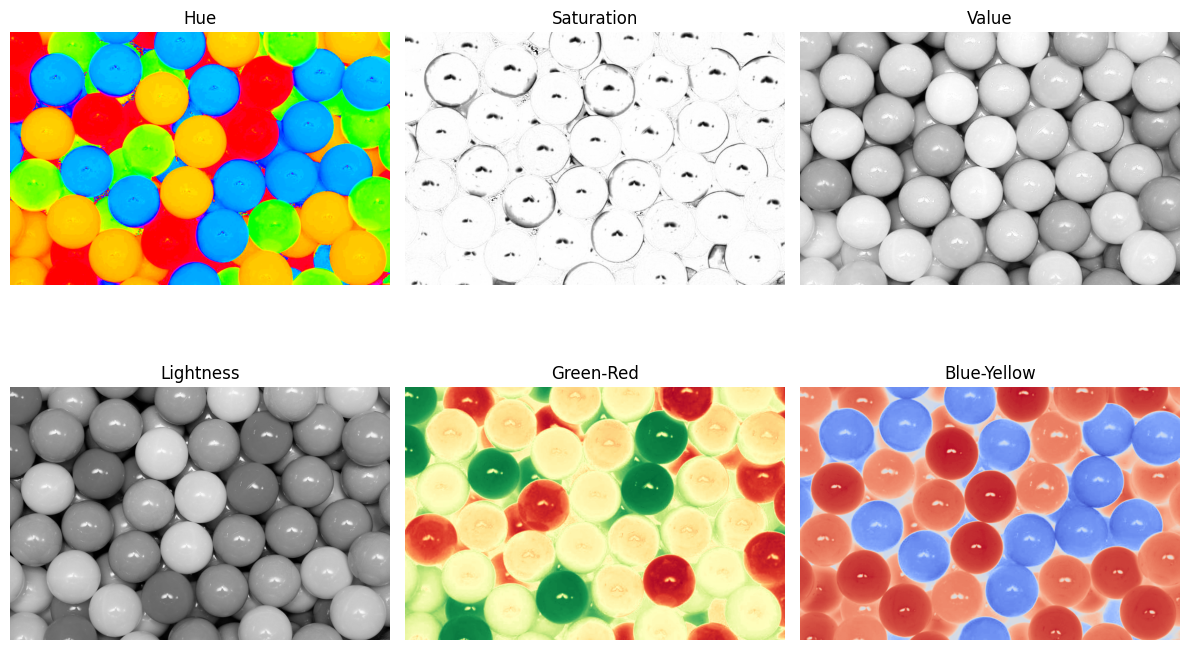

In [9]:
##########################################################
# 3. DISPLAY THE THREE CHANNELS OF EACH SPACE SIDE BY SIDE
##########################################################
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# HSV channels
axes[0,0].imshow(h, cmap='hsv'); axes[0,0].set_title("Hue"); axes[0,0].axis("off")
axes[0,1].imshow(s, cmap='gray'); axes[0,1].set_title("Saturation"); axes[0,1].axis("off")
axes[0,2].imshow(v, cmap='gray'); axes[0,2].set_title("Value"); axes[0,2].axis("off")

# LAB channels
axes[1,0].imshow(l, cmap='gray'); axes[1,0].set_title("Lightness"); axes[1,0].axis("off")
axes[1,1].imshow(a, cmap='RdYlGn'); axes[1,1].set_title("Green-Red"); axes[1,1].axis("off")
axes[1,2].imshow(b, cmap='coolwarm'); axes[1,2].set_title("Blue-Yellow"); axes[1,2].axis("off")

plt.tight_layout()
plt.show()

#### What each channel encodes
 HSV Channels:
1. Hue (S): Represents the pure color (0-180 in OpenCV, corresponding to 0-360 degrees),
  where different angles correspond to different colors (red, green, blue, etc.).
2. Saturation (S): Represents the intensity or purity of the color, from 0 (gray) to maximum (pure color).
3. Value (V): Represents the brightness of the color, from 0 (black) to maximum (full brightness).

LAB Channels:
1. L (Lightness): Represents the brightness from black (0) to white (100).
2. a: Represents the color dimension from green (negative) to red (positive).
3. b: Represents the color dimension from blue (negative) to yellow (positive).

### Why HSV is easier for colour-based segmentation than RGB:

In RGB, a colour is defined by three values for Red, Green, Blue (RGB) that are all highly correlated with each other and with intensity changes. Even small
variations in lighting or shadows can cause significant changes in all three RGB channels simultaneously. However, in HSV, the Hue channel encodes the
actual colour independently of brightness and saturation. This means that regardless of lighting conditions, a red object will always have a similar
hue value (around 0° or 180°), making it much easier to define a consistent range for colour segmentation. A range can be set on the Hue
channel, while Saturation and Value handle the intensity variations.

## Task 2. Noise and smoothing - a controlled experiment (4 marks)

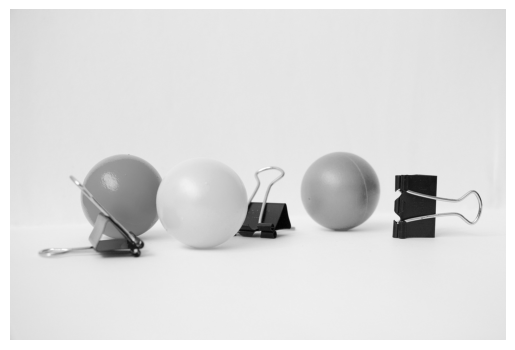

In [30]:
########################################
# LOAD IMAGE AND CHANGE IT TO GRAYSCALE
#######################################
gray_image = cv2.imread('images/color_balls.jpg', cv2.IMREAD_GRAYSCALE)
plt.axis('off')
plt.imshow(gray_image, cmap="gray")

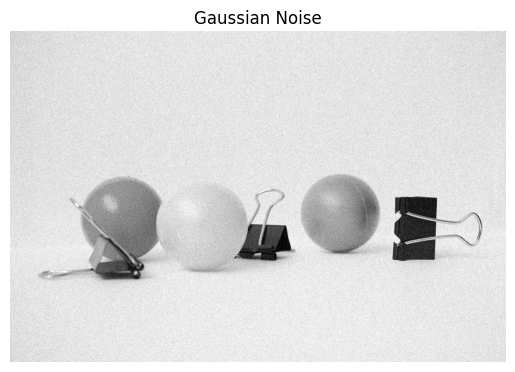

In [43]:
#########################################################################
# IMAGE WITH GAUSSIAN NOISE
#########################################################################
g_noise=np.random.normal(0, 15, gray_image.shape)

# Add noise safely
g_noisy_gray_image = gray_image.astype(np.float32) + g_noise

# Clip to [0,255] and convert back
g_noisy_gray_image_clipped = np.clip(g_noisy_gray_image, 0, 255).astype(np.uint8)
plt.title("Gaussian Noise")
plt.axis('off')
plt.imshow(g_noisy_gray_image_clipped, cmap="gray")

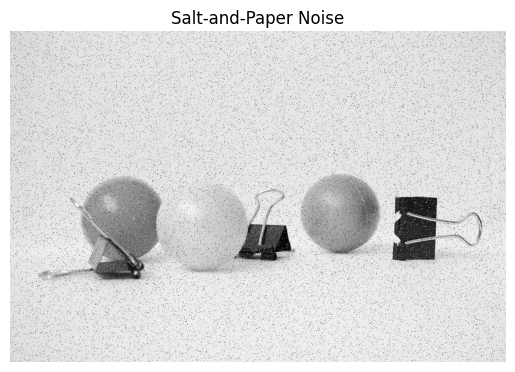

In [44]:
#########################################################################
# IMAGE WITH SALT-AND-PAPER NOISE
#########################################################################
# Copy image
sp_noisy_gray_image = gray_image.copy()

# Number of pixels to alter
num_pixels = int(0.05 * gray_image.size)

# Random coordinates
coords = [np.random.randint(0, i-1, num_pixels) for i in gray_image.shape]

# Set half to 0 (pepper), half to 255 (salt)
sp_noisy_gray_image[coords[0][:num_pixels//2], coords[1][:num_pixels//2]] = 0
sp_noisy_gray_image[coords[0][num_pixels//2:], coords[1][num_pixels//2:]] = 255
#sp_noisy_gray_image = sp_noisy_gray_image.astype(np.uint8)
plt.title("Salt-and-Paper Noise")
plt.axis('off')
plt.imshow(sp_noisy_gray_image, cmap='gray')

In [34]:
###########################################################
# PSNR function
###########################################################
def psnr(original, restored):
    mse = np.mean((original.astype(np.float32) - restored.astype(np.float32)) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    return 20 * np.log10(max_pixel / np.sqrt(mse))

In [35]:

kernel_sizes = [3, 5, 7]

results = []

for k in kernel_sizes:
    # Box filter
    restored_box_gauss = cv2.blur(g_noisy_gray_image_clipped, (k, k))
    restored_box_sp = cv2.blur(sp_noisy_gray_image, (k, k))
    results.append(("Box", "Gaussian", k, psnr(gray_image, restored_box_gauss)))
    results.append(("Box", "Salt-Pepper", k, psnr(gray_image, restored_box_sp)))

    # Gaussian filter
    restored_gauss_gauss = cv2.GaussianBlur(g_noisy_gray_image_clipped, (k, k), 0)
    restored_gauss_sp = cv2.GaussianBlur(sp_noisy_gray_image, (k, k), 0)
    results.append(("Gaussian", "Gaussian", k, psnr(gray_image, restored_gauss_gauss)))
    results.append(("Gaussian", "Salt-Pepper", k, psnr(gray_image, restored_gauss_sp)))

    # Median filter
    restored_median_gauss = cv2.medianBlur(g_noisy_gray_image_clipped, k)
    restored_median_sp = cv2.medianBlur(sp_noisy_gray_image, k)
    results.append(("Median", "Gaussian", k, psnr(gray_image, restored_median_gauss)))
    results.append(("Median", "Salt-Pepper", k, psnr(gray_image, restored_median_sp)))


In [36]:
#######################################
# RESULTS TABLE
#######################################
df = pd.DataFrame(results, columns=["Filter", "Noise Type", "Kernel Size", "PSNR"])
print(df.pivot_table(index=["Filter","Noise Type"], columns="Kernel Size", values="PSNR"))


Kernel Size                   3          5          7
Filter   Noise Type                                  
Box      Gaussian     33.417885  34.200100  33.326508
         Salt-Pepper  25.969662  28.692699  29.438532
Gaussian Gaussian     32.900440  34.488472  34.916885
         Salt-Pepper  25.168791  27.294378  28.867268
Median   Gaussian     31.997581  34.720791  34.983128
         Salt-Pepper  43.355595  39.762833  37.287071


From the PSNR results:
* For Gaussian noise, the Gaussian filter performs best because its smoothing kernel matches the statistical distribution of the noise which allows it to reduce the random fluctuations effectively while preserving the underlying image structure. The median filter also performs reasonably well, but the Gaussian filter is slightly more consistent across kernel sizes for this type of noise.
* For salt‑and‑pepper noise, the median filter performed best. Salt‑and‑pepper noise introduces extreme outliers by forcing pixels to black or white, and averaging filters such as box or Gaussian include those outliers in their calculations, which reduces their effectiveness. The median filter, by contrast, replaces each pixel with the median value of its neighbourhood, which naturally discards those extreme values. This makes it far more effective at restoring images corrupted by impulsive noise.

## Task 3. Sharpening with unsharp masking (2 marks)

In [ ]:
###########################################
# FUNCTION FOR UNSHARP MASKING
###########################################
def unsharp_mask(original, blurred, amount):
    sharpened = original + amount * (original - blurred)
    return np.clip(sharpened, 0, 255).astype(np.uint8)



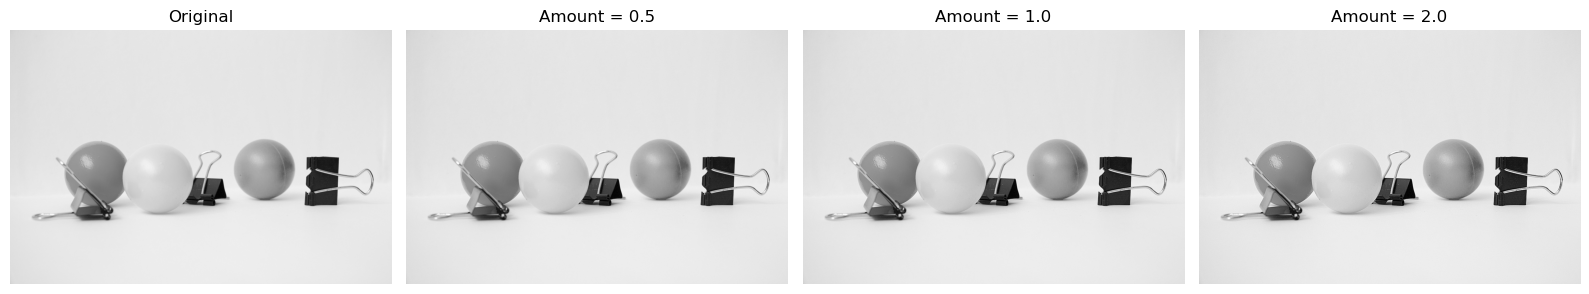

In [ ]:
# Load grayscale image
img = gray_image.copy()

# Convert to float for safe arithmetic
img_float = img.astype(np.float32)

# Blur the image (Gaussian blur works well)
blurred = cv2.GaussianBlur(img_float, (5, 5), 0)

# Difference image (edge emphasis)
#difference = img_float - blurred

# Apply with different amounts
sharpened_05 = unsharp_mask(img_float, blurred, 0.5)
sharpened_10 = unsharp_mask(img_float, blurred, 1.0)
sharpened_20 = unsharp_mask(img_float, blurred, 2.0)

# Display results
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
axes[0].imshow(img, cmap='gray'); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(sharpened_05, cmap='gray'); axes[1].set_title("Amount = 0.5"); axes[1].axis("off")
axes[2].imshow(sharpened_10, cmap='gray'); axes[2].set_title("Amount = 1.0"); axes[2].axis("off")
axes[3].imshow(sharpened_20, cmap='gray'); axes[3].set_title("Amount = 2.0"); axes[3].axis("off")
#axes[1].imshow(difference, cmap='gray'); axes[1].set_title("Difference (Edges)"); axes[1].axis("off")
plt.tight_layout()
plt.show()

## Task 4. Edge detection three ways (4 marks).

In [37]:
########################################################
# SOBEL - 2D CONVOLUTION IN NUMPY
#########################################################
# Load grayscale image
sob_gray_img = cv2.imread("images/spots.jpg", cv2.IMREAD_GRAYSCALE).astype(np.float32)

# Sobel kernels
sobel_x = np.array([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=np.float32)
sobel_y = np.array([[-1,-2,-1],[0,0,0],[1,2,1]], dtype=np.float32)

# Convolution (vectorised using cv2.filter2D)
gx = cv2.filter2D(sob_gray_img, -1, sobel_x)
gy = cv2.filter2D(sob_gray_img, -1, sobel_y)

# Gradient magnitude
grad_mag = np.sqrt(gx**2 + gy**2)

# Verify against cv2.Sobel
gx_cv = cv2.Sobel(sob_gray_img, cv2.CV_32F, 1, 0, ksize=3)
gy_cv = cv2.Sobel(sob_gray_img, cv2.CV_32F, 0, 1, ksize=3)
grad_mag_cv = np.sqrt(gx_cv**2 + gy_cv**2)

# Report maximum absolute difference
max_diff = np.max(np.abs(grad_mag - grad_mag_cv))
print("Max absolute difference:", max_diff)

Max absolute difference: 0.0


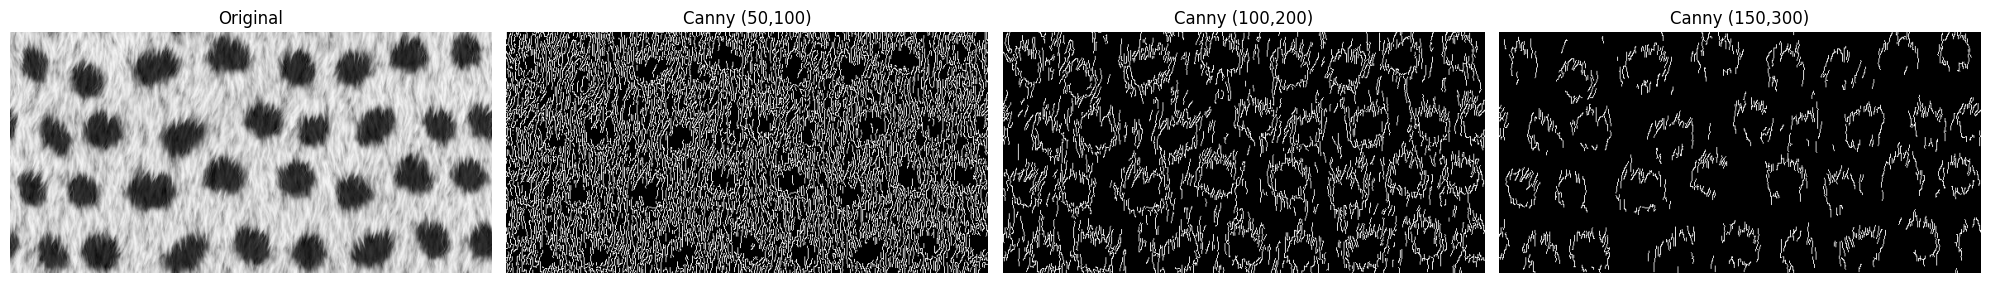

In [38]:
#################################################
# CANNY DETECTION WITH DIFFERENT THRESHOLDS
################################################

# Canny with three threshold pairs
edges1 = cv2.Canny(sob_gray_img.astype(np.uint8), 50, 100)    # conservative
edges2 = cv2.Canny(sob_gray_img.astype(np.uint8), 100, 200)   # balanced
edges3 = cv2.Canny(sob_gray_img.astype(np.uint8), 150, 300)   # aggressive

# results side by side
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(sob_gray_img, cmap='gray')
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(edges1, cmap='gray')
axes[1].set_title("Canny (50,100)")
axes[1].axis("off")

axes[2].imshow(edges2, cmap='gray')
axes[2].set_title("Canny (100,200)")
axes[2].axis("off")

axes[3].imshow(edges3, cmap='gray')
axes[3].set_title("Canny (150,300)")
axes[3].axis("off")

plt.tight_layout()
plt.show()

Effects of the thresholds are as follows:
* Thresholds (50, 100): Many edges, including weak ones and some noise, are kept.
* Thresholds (100, 200): Balanced map: strong edges are kept while suppressing weak isolated edges.
* Thresholds (150, 300): Only the strongest edges remain, giving a cleaner but sparser map.

This demonstrates the role of the two thresholds in hysteresis: the high threshold ensures only strong edges are kept, while the low threshold allows weak edges to survive if they connect to strong ones.

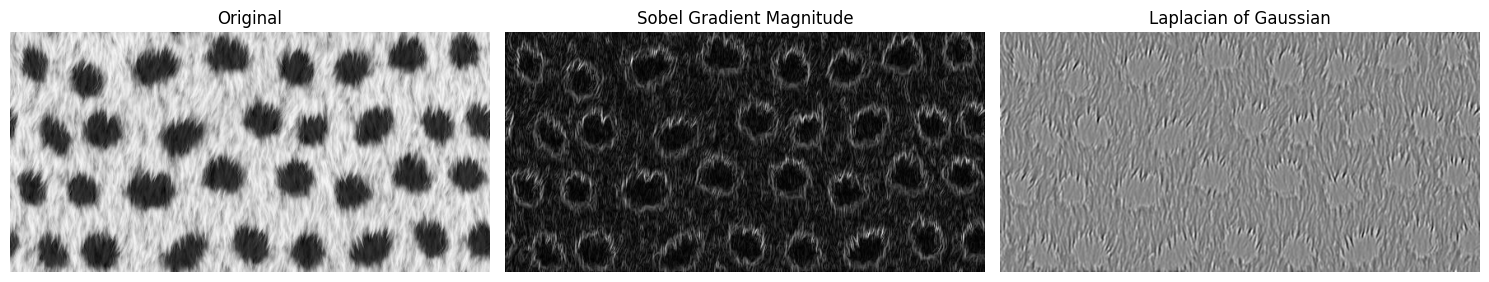

In [39]:
#################################################################
# LAPLACIAN OF GAUSSIAN (LOG)
##################################################################
# Load grayscale image
log_gray_image = cv2.imread("images/spots.jpg", cv2.IMREAD_GRAYSCALE).astype(np.float32)

# Sobel Gradient Magnitude
gx = cv2.Sobel(log_gray_image, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(log_gray_image, cv2.CV_32F, 0, 1, ksize=3)
sobel_mag = np.sqrt(gx**2 + gy**2)

# Laplacian of Gaussian
blurred = cv2.GaussianBlur(log_gray_image, (5,5), 0)
log_edges = cv2.Laplacian(blurred, cv2.CV_32F)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(log_gray_image, cmap='gray')
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(sobel_mag, cmap='gray')
axes[1].set_title("Sobel Gradient Magnitude")
axes[1].axis("off")

axes[2].imshow(log_edges, cmap='gray')
axes[2].set_title("Laplacian of Gaussian")
axes[2].axis("off")

plt.tight_layout()
plt.show()

The Sobel operator produces edge maps that seem to emphasise the strength and direction of intensity changes, as in the picture above, while the Laplacian of Gaussian has thinner, symmetric outlines. This difference in character reflects Sobel’s role as a first‑derivative detector and LoG’s role as a second‑derivative detector.

## Task 5. Morphology: from mask to object count (3 marks).

In [40]:
#################################################################################
# UTILITY FUNCTIONS
#################################################################################

def threshold_otsu(image):
    """Apply Otsu thresholding to get binary mask."""
    _, mask = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return mask

def erode(mask, ksize=3):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (ksize, ksize))
    return cv2.erode(mask, kernel, iterations=1)

def dilate(mask, ksize=3):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (ksize, ksize))
    return cv2.dilate(mask, kernel, iterations=1)

def opening(mask, ksize=3, shape=cv2.MORPH_RECT):
    kernel = cv2.getStructuringElement(shape, (ksize, ksize))
    return cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

def closing(mask, ksize=3, shape=cv2.MORPH_RECT):
    kernel = cv2.getStructuringElement(shape, (ksize, ksize))
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

def count_objects(mask, min_area=2000):
    """Count connected components larger than min_area."""
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask)
    valid = stats[1:, cv2.CC_STAT_AREA] > min_area   # ignore background
    count = np.sum(valid)
    return count, labels, stats, centroids

#################################################################################
# PIPELINE
#################################################################################

def morphology_pipeline(image_path, ksize=9, min_area=2000):
    # Load grayscale image
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    # Step 1: Threshold
    mask = threshold_otsu(img)

    # Step 2: Morphological operations (using elliptical kernel for coins)
    mask_opened = opening(mask, ksize, shape=cv2.MORPH_ELLIPSE)
    mask_closed = closing(mask_opened, ksize, shape=cv2.MORPH_ELLIPSE)

    # Step 3: Count objects with area filter
    count, labels, stats, centroids = count_objects(mask_closed, min_area)

    # Step 4: Show progression
    masks = [mask, mask_opened, mask_closed]
    titles = ["Threshold (Otsu)", "Opening", "Closing (Final)"]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, m, t in zip(axes, masks, titles):
        ax.imshow(m, cmap='gray')
        ax.set_title(t)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    print(f"Structuring element size: {ksize}x{ksize} (elliptical)")
    print(f"Final coin count: {count}")

    return count, centroids


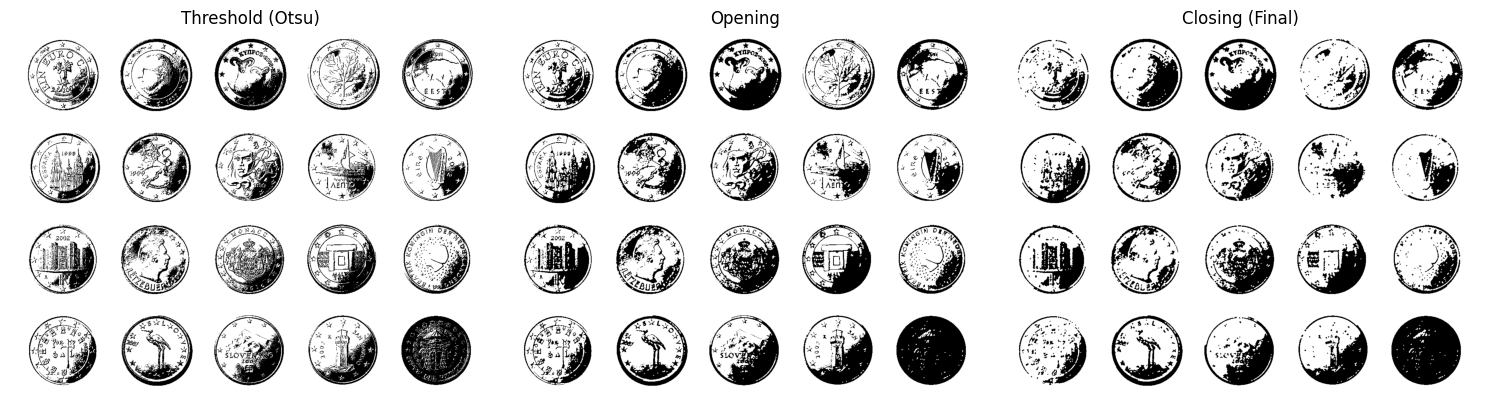

Structuring element size: 3x3 (elliptical)
Final coin count: 19


In [41]:
morph_img_path = "images/coins.jpg"
count, centroids = morphology_pipeline(morph_img_path, ksize=3, min_area=70)

The 3×3 elliptical kernel was chosen because it balances noise removal with object preservation: it cleans the mask without merging coins. The minimum area filter of 70 pixels ensures that only blobs large enough to be coins are counted, eliminating hundreds of tiny fragments.

## Task 6. Assemble a pipeline tool + reflection (2 marks).
Pipeline tool is `process.py` in the project folder